# Adult Income: audit, split, EDA and cleaning (Phases 1 to 4)

In [1]:
import pandas as pd
import numpy as np
from sklearn.datasets import fetch_openml

adult = fetch_openml("adult", version=2, as_frame=True)
df = adult.frame
df.to_csv("../data/raw/adult.csv", index=False)
print(df.shape)
df.head()

(48842, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


In [2]:
df.columns


Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'class'],
      dtype='str')

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             48842 non-null  int64   
 1   workclass       46043 non-null  category
 2   fnlwgt          48842 non-null  int64   
 3   education       48842 non-null  category
 4   education-num   48842 non-null  int64   
 5   marital-status  48842 non-null  category
 6   occupation      46033 non-null  category
 7   relationship    48842 non-null  category
 8   race            48842 non-null  category
 9   sex             48842 non-null  category
 10  capital-gain    48842 non-null  int64   
 11  capital-loss    48842 non-null  int64   
 12  hours-per-week  48842 non-null  int64   
 13  native-country  47985 non-null  category
 14  class           48842 non-null  category
dtypes: category(9), int64(6)
memory usage: 2.7 MB


In [4]:
print(df.isna().sum())


age                  0
workclass         2799
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        2809
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     857
class                0
dtype: int64


In [5]:
print(df.isnull().mean()*100)

age               0.000000
workclass         5.730724
fnlwgt            0.000000
education         0.000000
education-num     0.000000
marital-status    0.000000
occupation        5.751198
relationship      0.000000
race              0.000000
sex               0.000000
capital-gain      0.000000
capital-loss      0.000000
hours-per-week    0.000000
native-country    1.754637
class             0.000000
dtype: float64


In [6]:
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,48842.0,NaN,NaN,NaN,38.643585,13.71051,17.0,28.0,37.0,48.0,90.0
workclass,46043,8,Private,33906,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fnlwgt,48842.0,NaN,NaN,NaN,189664.134597,105604.025423,12285.0,117550.5,178144.5,237642.0,1490400.0
education,48842,16,HS-grad,15784,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education-num,48842.0,NaN,NaN,NaN,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
marital-status,48842,7,Married-civ-spouse,22379,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupation,46033,14,Prof-specialty,6172,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relationship,48842,6,Husband,19716,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,48842,5,White,41762,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,48842,2,Male,32650,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:

df.select_dtypes(include='number').skew()

age                0.557580
fnlwgt             1.438892
education-num     -0.316525
capital-gain      11.894659
capital-loss       4.569809
hours-per-week     0.238750
dtype: float64

In [8]:
text_cols = df.select_dtypes(include=["object", "category"]).columns
for col in text_cols:
    print(df[col].value_counts(dropna=False).head(6))
    print()

workclass
Private             33906
Self-emp-not-inc     3862
Local-gov            3136
NaN                  2799
State-gov            1981
Self-emp-inc         1695
Name: count, dtype: int64

education
HS-grad         15784
Some-college    10878
Bachelors        8025
Masters          2657
Assoc-voc        2061
11th             1812
Name: count, dtype: int64

marital-status
Married-civ-spouse       22379
Never-married            16117
Divorced                  6633
Separated                 1530
Widowed                   1518
Married-spouse-absent      628
Name: count, dtype: int64

occupation
Prof-specialty     6172
Craft-repair       6112
Exec-managerial    6086
Adm-clerical       5611
Sales              5504
Other-service      4923
Name: count, dtype: int64

relationship
Husband           19716
Not-in-family     12583
Own-child          7581
Unmarried          5125
Wife               2331
Other-relative     1506
Name: count, dtype: int64

race
White                 41762
Black      

In [9]:
missing = df.isna().sum()
percent = (df.isna().mean() * 100).round(2)
print(pd.DataFrame({"missing": missing, "percent": percent}).sort_values("missing", ascending=False))

                missing  percent
occupation         2809     5.75
workclass          2799     5.73
native-country      857     1.75
fnlwgt                0     0.00
education             0     0.00
education-num         0     0.00
age                   0     0.00
marital-status        0     0.00
relationship          0     0.00
sex                   0     0.00
race                  0     0.00
capital-gain          0     0.00
capital-loss          0     0.00
hours-per-week        0     0.00
class                 0     0.00


In [10]:
for col in df.select_dtypes(include=["object", "category"]).columns:
    print(col, (df[col].astype(str).str.strip() == "?").sum())

workclass 0
education 0
marital-status 0
occupation 0
relationship 0
race 0
sex 0
native-country 0
class 0


In [11]:
print(df.duplicated().sum())

52


In [12]:
dups = df[df.duplicated(keep=False)]
print(dups.shape)
dups.sort_values(list(df.columns)).head(6)

(101, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
4152,17,Private,153021,12th,8,Never-married,Sales,Own-child,White,Female,0,0,20,United-States,<=50K
40948,17,Private,153021,12th,8,Never-married,Sales,Own-child,White,Female,0,0,20,United-States,<=50K
3900,18,Self-emp-inc,378036,12th,8,Never-married,Farming-fishing,Own-child,White,Male,0,0,10,United-States,<=50K
15960,18,Self-emp-inc,378036,12th,8,Never-married,Farming-fishing,Own-child,White,Male,0,0,10,United-States,<=50K
33954,19,Private,97261,HS-grad,9,Never-married,Farming-fishing,Not-in-family,White,Male,0,0,40,United-States,<=50K
34979,19,Private,97261,HS-grad,9,Never-married,Farming-fishing,Not-in-family,White,Male,0,0,40,United-States,<=50K


## Phase 1: Load and audit

**Goal:** Load Adult and find the messy parts before any learning.

**Finding:**
- 48842 rows, 14 features, target `class` (about 76% `<=50K`, 24% `>50K`)
- Missing values: occupation 5.75%, workclass 5.73%, native-country 1.75%. No hidden "?" in any text column
- 52 duplicate rows (about 0.11%), same `fnlwgt`, so real copies

**Decision:**
- Keep the rows with missing values and fill them inside the Pipeline, after the split
- Drop the 52 duplicates before the split
- Still to check: skew in capital-gain/loss, `fnlwgt`, redundant `education`/`education-num`

In [13]:
print(df[col].value_counts(dropna=False).head(6))

class
<=50K    37155
>50K     11687
Name: count, dtype: int64


In [14]:
import pandas as pd

df = pd.read_csv("../data/raw/adult.csv")
df = df.drop_duplicates().reset_index(drop=True)
X = df.drop(columns="class")
y = df["class"]
print(df.shape, X.shape, y.shape)

(48790, 15) (48790, 14) (48790,)


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test , y_train , y_test = train_test_split(X,y, stratify=y,test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape, y_test.shape, y_train.shape)



(39032, 14) (9758, 14) (9758,) (39032,)


In [16]:
print(y_train.value_counts(normalize=True).round(3))
print(y_test.value_counts(normalize=True).round(3))

class
<=50K    0.761
>50K     0.239
Name: proportion, dtype: float64
class
<=50K    0.761
>50K     0.239
Name: proportion, dtype: float64


## Phase 2: Stratified split

**Goal:** Split before anything is learned, so the test set stays honest.

**Finding:**
- 52 duplicates dropped, 48790 rows left
- Train 39032 rows, test 9758 rows (80/20), `stratify=y`, `random_state=42`
- Class share is the same in train and test (about 76% / 24%)

**Decision:**
- `X_test` and `y_test` stay locked until Phase 11
- EDA, cleaning and tuning use `X_train` and `y_train` only

class
<=50K    29687
>50K      9345
Name: count, dtype: int64
class
<=50K    0.761
>50K     0.239
Name: count, dtype: float64


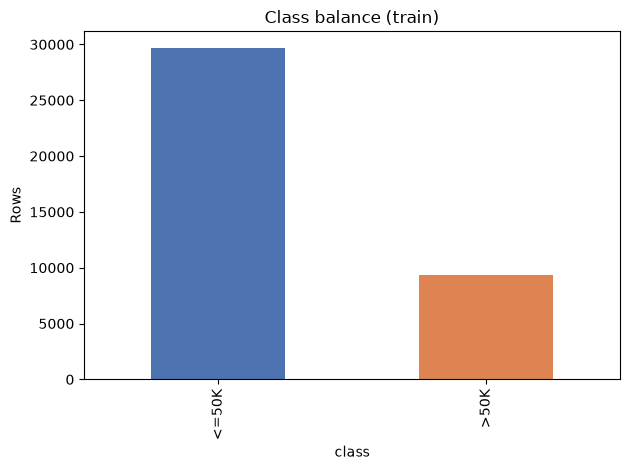

In [17]:
import matplotlib.pyplot as plt

counts = y_train.value_counts()
print(counts)
print((counts / counts.sum()).round(3))

counts.plot(kind="bar", color=["#4C72B0", "#DD8452"])
plt.title("Class balance (train)")
plt.ylabel("Rows")
plt.tight_layout()
plt.savefig("../reports/figures/class_balance.png", dpi=150)
plt.show()

In [18]:
cols = ["capital-gain", "capital-loss"]
print(X_train[cols].describe().round(1))
print((X_train[cols] == 0).mean().round(3))
print((X_train["capital-gain"] == 99999).sum())

       capital-gain  capital-loss
count       39032.0       39032.0
mean         1090.0          89.0
std          7558.6         405.9
min             0.0           0.0
25%             0.0           0.0
50%             0.0           0.0
75%             0.0           0.0
max         99999.0        4356.0
capital-gain    0.918
capital-loss    0.952
dtype: float64
202


In [19]:
big = X_train["capital-gain"] == 99999
print(y_train[big].value_counts(normalize=True).round(3))
print(X_train.loc[~big & (X_train["capital-gain"] > 0), "capital-gain"].max())

class
>50K    1.0
Name: proportion, dtype: float64
41310


In [20]:
check = X_train.groupby("education")["education-num"].nunique()
print(check.max())
print(X_train[["education", "education-num"]].drop_duplicates().sort_values("education-num"))

1
          education  education-num
48265     Preschool              1
47749       1st-4th              2
44459       5th-6th              3
39122       7th-8th              4
18128           9th              5
41045          10th              6
19524          11th              7
41807          12th              8
25013       HS-grad              9
150    Some-college             10
14940     Assoc-voc             11
37040    Assoc-acdm             12
13113     Bachelors             13
4129        Masters             14
30382   Prof-school             15
2571      Doctorate             16


In [21]:
print(X_train["fnlwgt"].describe().round(0))
print(X_train["fnlwgt"].corr(y_train.eq(">50K").astype(int)).round(3))

count      39032.0
mean      189747.0
std       105773.0
min        12285.0
25%       117767.0
50%       178253.0
75%       237469.0
max      1490400.0
Name: fnlwgt, dtype: float64
-0.006


In [22]:
cols = ["workclass", "occupation", "native-country"]
miss = X_train[cols].isna()
print(miss.value_counts())

workclass  occupation  native-country
False      False       False             36152
True       True        False              2198
False      False       True                639
True       True        True                 35
False      True        False                 8
Name: count, dtype: int64


In [23]:
nc = X_train["native-country"].value_counts(normalize=True)
print(X_train["native-country"].nunique())
print(nc.head(5).round(3)*100)
print((nc < 0.01).sum())

41
native-country
United-States    91.3
Mexico            2.0
Philippines       0.6
Germany           0.5
Puerto-Rico       0.4
Name: proportion, dtype: float64
39


## Phase 3: EDA (train only)

**Goal:** Understand imbalance, skew, redundancy and missing values using train only.

**Finding:**
- Class share 76.1% / 23.9%; "always <=50K" gives 76.1% accuracy
- capital-gain 91.8% and capital-loss 95.2% are zeros; 202 rows have gain 99999, all >50K (cap code, probably)
- education and education-num are the same information; fnlwgt has correlation -0.006 with the target
- workclass and occupation are missing together (2233 rows); native-country is a separate gap

**Decision:**
- Keep 99999 rows; keep education-num, drop education; fnlwgt is a drop candidate (test in Phase 5)
- Compare "Missing" constant vs most frequent; group rare countries in Phase 5

In [24]:
import pandas as pd
from sklearn.preprocessing import FunctionTransformer
from adult_income_ensemble.cleaning import clean_adult

cleaner = FunctionTransformer(clean_adult)
test = pd.DataFrame({"workclass": [" Private", "?"], "age": [30, 40]})
print(cleaner.fit_transform(test))


  workclass  age
0   Private   30
1       NaN   40


In [25]:
cleaned = clean_adult(X_train)
print(X_train.shape == cleaned.shape)
print(X_train.isna().sum().sum(), cleaned.isna().sum().sum())
print(len(X_train.select_dtypes(include=["object", "category", "string"]).columns))

True
5148 5148
8


## Phase 4: Cleaning step

**Goal:** Build a cleaning step that works inside the Pipeline.

**Finding:**
- `clean_adult` (in `src/adult_income_ensemble/cleaning.py`) removes spaces and turns "?" into NaN
- On the real train data it changes nothing (shape equal, 5148 missing before and after, 8 text columns found)

**Decision:**
- Keep the cleaner as the first Pipeline step (wrapped in `FunctionTransformer` in Phase 5)
- Dropping `education` and `fnlwgt` is decided in the ColumnTransformer in Phase 5

In [26]:
numeric_cols = ["age", "education-num", "capital-gain", "capital-loss", "hours-per-week"]
cat_cols = ["workclass", "marital-status", "occupation", "relationship",
            "race", "sex", "native-country"]
dropped_cols = ["education", "fnlwgt"]

all_cols = numeric_cols + cat_cols + dropped_cols
print(len(all_cols), set(all_cols) == set(X_train.columns))
print(X_train[cat_cols].dtypes)

14 True
workclass         str
marital-status    str
occupation        str
relationship      str
race              str
sex               str
native-country    str
dtype: object


In [27]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

num_out = numeric_pipe.fit_transform(X_train[numeric_cols])
print(num_out.shape)
print(num_out.mean(axis=0).round(2))
print(num_out.std(axis=0).round(2))

(39032, 5)
[ 0.  0.  0.  0. -0.]
[1. 1. 1. 1. 1.]


In [28]:
numeric_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('impute', ...), ('scale', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['age','education-num','capital-gain','capital-loss','hours-per-week']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"

In [29]:
from sklearn.preprocessing import OneHotEncoder

cat_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                             min_frequency=0.01, sparse_output=False)),
])

cat_out = cat_pipe.fit_transform(X_train[cat_cols])
print(cat_out.shape)
names = cat_pipe.get_feature_names_out()
print(len(names))
print(names[:8])

(39032, 45)
45
['workclass_Federal-gov' 'workclass_Local-gov' 'workclass_Missing'
 'workclass_Private' 'workclass_Self-emp-inc' 'workclass_Self-emp-not-inc'
 'workclass_State-gov' 'workclass_infrequent_sklearn']


United-States -> [1, 0, 0]
Mexico        -> [0, 1, 0]
Peru          -> [0, 0, 1]   <- goes to "infrequent"
Fiji (new)    -> [0, 0, 1]   <- also goes to "infrequent"

In [30]:
cat_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('impute', ...), ('onehot', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['workclass','marital-status','occupation',...,'race','sex', 'native-country']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'constant'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",'Missing'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or 

In [31]:
from sklearn.compose import ColumnTransformer

preprocess = ColumnTransformer([
    ("num", numeric_pipe, numeric_cols),
    ("cat", cat_pipe, cat_cols),
], remainder="drop")

prep_pipe = Pipeline([
    ("clean", FunctionTransformer(clean_adult)),
    ("prep", preprocess),
])

prep_out = prep_pipe.fit_transform(X_train)
print(prep_out.shape)
print(prep_pipe.named_steps["prep"].get_feature_names_out()[:7])

(39032, 50)
['num__age' 'num__education-num' 'num__capital-gain' 'num__capital-loss'
 'num__hours-per-week' 'cat__workclass_Federal-gov'
 'cat__workclass_Local-gov']


## Phase 5: Preprocessing recipes

**Goal:** Build the front half of the Pipeline so nothing is learned outside it.

**Finding:**
- 5 numeric columns -> median fill + StandardScaler (means 0, std 1 on train)
- 7 text columns -> constant "Missing" fill + OneHotEncoder with min_frequency=0.01 (45 columns)
- clean_adult + ColumnTransformer give 50 columns from 14

**Decision:**
- Drop `education` (same as education-num) and `fnlwgt` for now
- Test later: fnlwgt back in, "Missing" vs most frequent, log1p on capital columns

## Phase 6: Baselines

In [32]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

y_train_bin = (y_train == ">50K").astype(int)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

dummy = Pipeline([
    ("prep", prep_pipe),
    ("model", DummyClassifier(strategy="most_frequent")),
])

res = cross_validate(dummy, X_train, y_train_bin, cv=cv,
                     scoring=["accuracy", "f1"])
print(res["test_accuracy"].round(3))
print(res["test_f1"].round(3))

[0.761 0.761 0.761 0.761 0.761]
[0. 0. 0. 0. 0.]


In [33]:
from sklearn.linear_model import LogisticRegression

logreg = Pipeline([
    ("prep", prep_pipe),
    ("model", LogisticRegression(max_iter=1000)),
])

metrics = ["accuracy", "f1", "average_precision"]
res = cross_validate(logreg, X_train, y_train_bin, cv=cv, scoring=metrics)

for m in metrics:
    s = res[f"test_{m}"]
    print(m, "mean", s.mean().round(3), "std", s.std().round(3),
          "noise", (s.std() / 5**0.5).round(4))

accuracy mean 0.853 std 0.001 noise 0.0006
f1 mean 0.662 std 0.004 noise 0.0018
average_precision mean 0.768 std 0.004 noise 0.002


## Phase 6: Baselines

**Goal:** Set the floor and a simple first model, on the same 5 folds.

**Finding:**
- Dummy (always <=50K): accuracy 0.761, F1 0.000
- Logistic Regression: accuracy 0.853, F1 0.662, PR-AUC 0.768 (noise below 0.002 for all)

**Decision:**
- Logistic Regression is the baseline every later model must beat by more than the noise